# Medicine Recommendation System — Model Comparison & Tuning
**CS619 Final Year Project · Group S26PROJECTFEF30 · Supervisor: Dr. Mushtaq Hussain**

This notebook implements the *Model Training, Testing, Fine-Tuning and Optimisation* phase of the SRS
(**FR-01 – FR-16**). It extends the prototype notebook (`training.ipynb`, Random Forest only) by

1. cleaning the data exactly as the SRS says (missing values, **duplicate removal**, encoding),
2. training and comparing **Decision Tree, Random Forest, SVM, XGBoost, a scikit-learn neural network (MLP) and a Keras deep neural network**,
3. tuning with **GridSearchCV** and validating with **5-fold cross-validation**,
4. reporting accuracy, precision, recall and F1, and
5. saving the selected model as a `.pkl` bundle that the Streamlit app loads.

All reusable logic lives in `trainer.py`, so the Admin panel of the app retrains models with the same code.

## 1. Setup

In [1]:
import os, sys, subprocess, json, time, warnings
warnings.filterwarnings("ignore")

REPO_URL = "https://github.com/sajidiqbalCS619/Medicine-recommendation-system-CS619.git"
if "google.colab" in sys.modules:                      # running in Google Colab
    if not os.path.exists("/content/repo"):
        subprocess.run(["git", "clone", REPO_URL, "/content/repo"], check=True)
    os.chdir("/content/repo")
elif os.path.basename(os.getcwd()) == "Notebooks":     # running locally from Notebooks/
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import accuracy_score, confusion_matrix
import trainer

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
os.makedirs("Models/versions", exist_ok=True); os.makedirs("Notebooks/figures", exist_ok=True)
print("Working directory:", os.getcwd())

Working directory: /home/claude/repo


## 2. Load and inspect the dataset (FR-01)

In [2]:
raw = trainer.load_dataset("Datasets/Training.csv")
print("Shape:", raw.shape)
print("Missing values:", int(raw.isna().sum().sum()))
print("Diseases:", raw["prognosis"].nunique(), "| rows per disease:", raw["prognosis"].value_counts().unique())
raw.head(3)

Shape: (4920, 133)
Missing values: 0
Diseases: 41 | rows per disease: [120]


,itching,skin_rash,nodal_skin_eruptions,continuous_sneezing,shivering,chills,joint_pain,stomach_pain,acidity,ulcers_on_tongue,muscle_wasting,vomiting,burning_micturition,spotting_ urination,fatigue,...,blood_in_sputum,prominent_veins_on_calf,palpitations,painful_walking,pus_filled_pimples,blackheads,scurring,skin_peeling,silver_like_dusting,small_dents_in_nails,inflammatory_nails,blister,red_sore_around_nose,yellow_crust_ooze,prognosis
0,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,Fungal infection
1,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,Fungal infection
2,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,Fungal infection


## 3. Pre-processing (FR-02 – FR-05)
`clean_dataset` strips column names, fills missing values, binarises the symptom flags, **removes duplicate records (FR-03)**
and label-encodes the disease names (FR-05).

In [3]:
X, y, report = trainer.clean_dataset(raw, dedupe=True)
print(json.dumps(report, indent=2))

{
  "rows_in": 4920,
  "cols_in": 133,
  "unnamed_columns_dropped": 0,
  "missing_values_filled": 0,
  "empty_symptom_columns_dropped": 1,
  "duplicates_removed": 4616,
  "rows_out": 304,
  "n_symptoms": 131,
  "n_diseases": 41,
  "min_rows_per_disease": 5,
  "max_rows_per_disease": 10,
  "avg_symptoms_per_row": 7.65
}


### Finding: the raw data hides a leakage problem
4,616 of the 4,920 rows are exact duplicates; only **304 unique symptom patterns** exist.
If we split the *raw* data 80/20, almost every test row also appears in the training set, so a 100 % score proves very little.

In [4]:
Xr = raw.drop(columns=[c for c in raw.columns if c.startswith("Unnamed")] + ["prognosis"])
yr = raw["prognosis"]
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(Xr, yr, test_size=0.2, random_state=42, stratify=yr)
train_patterns = set(map(tuple, Xr_tr.values))
leak = np.mean([tuple(r) in train_patterns for r in Xr_te.values])
print(f"Raw 80/20 split: {leak*100:.1f}% of test rows are exact copies of training rows")
rf_raw = RandomForestClassifier(200, random_state=42).fit(Xr_tr, yr_tr)
print(f"Prototype-style RF accuracy on the raw split: {accuracy_score(yr_te, rf_raw.predict(Xr_te))*100:.1f}%  (inflated by leakage)")

Raw 80/20 split: 100.0% of test rows are exact copies of training rows


Prototype-style RF accuracy on the raw split: 100.0%  (inflated by leakage)


### Finding: chat users type fewer symptoms than the training rows contain
Training rows have on average ~7.7 symptoms, but a chatbot user typically types 2–4.
We simulate this by keeping only *k* random symptoms of each test row.

In [5]:
y_enc, le = trainer.encode_labels(y)
Xv = X.values.astype(int)
X_tr, X_te, y_tr, y_te = train_test_split(Xv, y_enc, test_size=0.2, random_state=42, stratify=y_enc)
print("Train rows:", len(y_tr), "| Test rows:", len(y_te), "(no duplicates, no overlap)")

baseline = RandomForestClassifier(200, random_state=42).fit(X_tr, y_tr)      # prototype settings
base_m = trainer.evaluate(baseline, X_te, y_te)
print({k: round(v, 3) for k, v in base_m.items()})

Train rows: 243 | Test rows: 61 (no duplicates, no overlap)


{'accuracy': 1.0, 'precision': 1.0, 'recall': 1.0, 'f1': 1.0, 'f1_macro': 1.0, 'acc_2_symptoms': 0.538, 'acc_3_symptoms': 0.685, 'acc_4_symptoms': 0.818}


The baseline reaches 100 % when all symptoms are given, but only about **54 % with 2 symptoms and 69 % with 3**.
To fix this we **augment the training part only** with random symptom subsets (symptom dropout). This is also a
regulariser, which addresses the brief's requirement to *reduce over-fitting*. The test part is never augmented.

## 4. Train, tune (GridSearchCV) and cross-validate five classical models (FR-06 – FR-15)

In [6]:
t0 = time.time()
run = trainer.train_and_compare(X, y, tune=True, augment=True, n_aug=30, progress=print)
print(f"\nDone in {time.time()-t0:.0f}s | train rows {run['split']['train_rows']} -> "
      f"{run['split']['augmented_train_rows']} after augmentation | test rows {run['split']['test_rows']}")

Training Random Forest ...


  Random Forest: test acc 1.000, CV robust 0.954
Training Decision Tree ...


  Decision Tree: test acc 1.000, CV robust 0.926
Training SVM ...


  SVM: test acc 1.000, CV robust 0.949
Training Neural Network (MLP) ...


  Neural Network (MLP): test acc 1.000, CV robust 0.957
Training XGBoost ...


  XGBoost: test acc 1.000, CV robust 0.951

Done in 356s | train rows 243 -> 7533 after augmentation | test rows 61


## 5. Deep learning: Keras neural network
A feed-forward network (132 → 256 → 128 → 41, ReLU, dropout 0.3, softmax) trained with Adam and early stopping.
It uses the same split and the same augmentation as the other models.

In [7]:
import os; os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
tf.keras.utils.set_random_seed(42)
print("TensorFlow", tf.__version__)

def build_dnn(n_in, n_out):
    m = keras.Sequential([
        layers.Input((n_in,)),
        layers.Dense(256, activation="relu"), layers.Dropout(0.3),
        layers.Dense(128, activation="relu"), layers.Dropout(0.3),
        layers.Dense(n_out, activation="softmax")])
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

def fit_dnn(Xa, ya, n_out, seed=42):
    # hold out 15% of the ORIGINAL rows for early stopping, then augment each part
    rng = np.random.default_rng(seed); idx = rng.permutation(len(ya)); cut = int(len(ya) * 0.85)
    tr, va = idx[:cut], idx[cut:]
    Xt, yt = trainer.augment_symptom_subsets(Xa[tr], ya[tr], 30, 2, seed)
    Xv_, yv_ = trainer.augment_symptom_subsets(Xa[va], ya[va], 5, 2, seed + 1)
    model = build_dnn(Xa.shape[1], n_out)
    hist = model.fit(Xt, yt, validation_data=(Xv_, yv_), epochs=60, batch_size=128, verbose=0,
                     callbacks=[keras.callbacks.EarlyStopping(patience=8, restore_best_weights=True)])
    return model, hist

class KerasClf:                      # tiny adapter so trainer.evaluate() works
    def __init__(self, m): self.m = m
    def predict_proba(self, X): return self.m.predict(np.asarray(X), verbose=0)
    def predict(self, X): return self.predict_proba(X).argmax(1)

n_classes = len(le.classes_)
t0 = time.time()
dnn, hist = fit_dnn(X_tr, y_tr, n_classes)
dnn_time = time.time() - t0
dnn_clf = KerasClf(dnn)
dnn_test = trainer.evaluate(dnn_clf, X_te, y_te)
print("Epochs trained:", len(hist.history["loss"]), "| seconds:", round(dnn_time, 1))
print({k: round(v, 3) for k, v in dnn_test.items()})

I0000 00:00:1792275167.548192    8420 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1792275168.368664    8420 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0


Epochs trained: 38 | seconds: 6.8
{'accuracy': 0.984, 'precision': 0.989, 'recall': 0.984, 'f1': 0.983, 'f1_macro': 0.987, 'acc_2_symptoms': 0.762, 'acc_3_symptoms': 0.89, 'acc_4_symptoms': 0.961}


{'cv_accuracy_mean': 1.0, 'cv_accuracy_std': 0.0, 'cv_acc_3_symptoms_mean': 0.941}


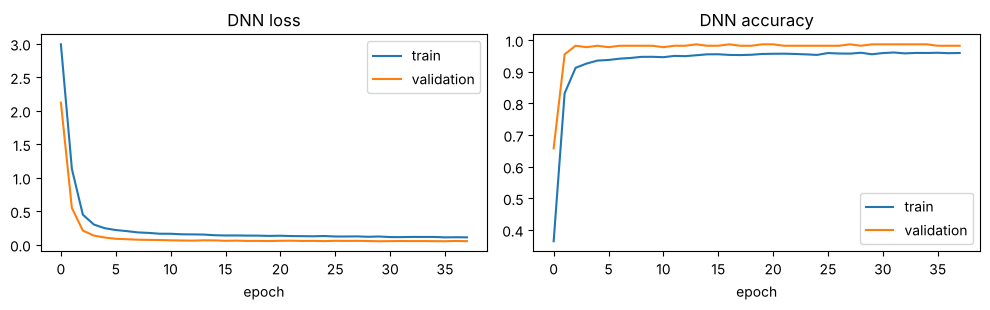

In [8]:
# 5-fold cross-validation for the DNN (augmentation inside each training fold only)
skf = StratifiedKFold(5, shuffle=True, random_state=42)
full, k3 = [], []
for tr, va in skf.split(Xv, y_enc):
    m, _ = fit_dnn(Xv[tr], y_enc[tr], n_classes)
    c = KerasClf(m)
    full.append(accuracy_score(y_enc[va], c.predict(Xv[va])))
    k3.append(accuracy_score(y_enc[va], c.predict(trainer.keep_k_symptoms(Xv[va], 3, np.random.default_rng(0)))))
dnn_cv = dict(cv_accuracy_mean=np.mean(full), cv_accuracy_std=np.std(full), cv_acc_3_symptoms_mean=np.mean(k3))
print({k: round(float(v), 3) for k, v in dnn_cv.items()})

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(hist.history["loss"], label="train"); ax[0].plot(hist.history["val_loss"], label="validation")
ax[0].set_title("DNN loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(hist.history["accuracy"], label="train"); ax[1].plot(hist.history["val_accuracy"], label="validation")
ax[1].set_title("DNN accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.savefig("Notebooks/figures/dnn_training_curves.png", dpi=150); plt.show()

## 6. Comparison table (FR-10, FR-16)

In [9]:
table = trainer.metrics_table(run)
base_row = {"Accuracy": base_m["accuracy"], "Precision": base_m["precision"], "Recall": base_m["recall"], "F1": base_m["f1"],
            "Acc@2 symptoms": base_m["acc_2_symptoms"], "Acc@3 symptoms": base_m["acc_3_symptoms"], "Acc@4 symptoms": base_m["acc_4_symptoms"],
            "Train acc": 1.0, "Overfit gap": 0.0}
dnn_row = {"Accuracy": dnn_test["accuracy"], "Precision": dnn_test["precision"], "Recall": dnn_test["recall"], "F1": dnn_test["f1"],
           "Acc@2 symptoms": dnn_test["acc_2_symptoms"], "Acc@3 symptoms": dnn_test["acc_3_symptoms"], "Acc@4 symptoms": dnn_test["acc_4_symptoms"],
           "CV acc (mean)": dnn_cv["cv_accuracy_mean"], "CV acc (std)": dnn_cv["cv_accuracy_std"], "CV acc@3 (mean)": dnn_cv["cv_acc_3_symptoms_mean"],
           "Train sec": round(dnn_time, 1)}
full_table = pd.concat([pd.DataFrame({"Baseline RF (prototype settings, no augmentation)": base_row}).T,
                        table.drop(columns=["Best params"]),
                        pd.DataFrame({"Deep Neural Network (Keras)": dnn_row}).T])
full_table.index.name = "Model"
show = ["Accuracy","Precision","Recall","F1","Acc@2 symptoms","Acc@3 symptoms","Acc@4 symptoms","CV acc (mean)","CV acc@3 (mean)","Overfit gap","Selected"]
full_table[show].round(3)

,Accuracy,Precision,Recall,F1,Acc@2 symptoms,Acc@3 symptoms,Acc@4 symptoms,CV acc (mean),CV acc@3 (mean),Overfit gap,Selected
Model,,,,,,,,,,,
"Baseline RF (prototype settings, no augmentation)",1.000,1.000,1.000,1.000,0.538,0.685,0.818,NaN,NaN,0.0,NaN
Random Forest,1.000,1.000,1.000,1.000,0.730,0.870,0.939,1.0,0.908,0.0,yes
Decision Tree,1.000,1.000,1.000,1.000,0.700,0.815,0.866,1.0,0.852,0.0,
SVM,1.000,1.000,1.000,1.000,0.757,0.870,0.949,1.0,0.898,0.0,
Neural Network (MLP),1.000,1.000,1.000,1.000,0.752,0.895,0.962,1.0,0.914,0.0,
XGBoost,1.000,1.000,1.000,1.000,0.723,0.848,0.931,1.0,0.901,0.0,
Deep Neural Network (Keras),0.984,0.989,0.984,0.983,0.762,0.890,0.961,1.0,0.941,NaN,NaN


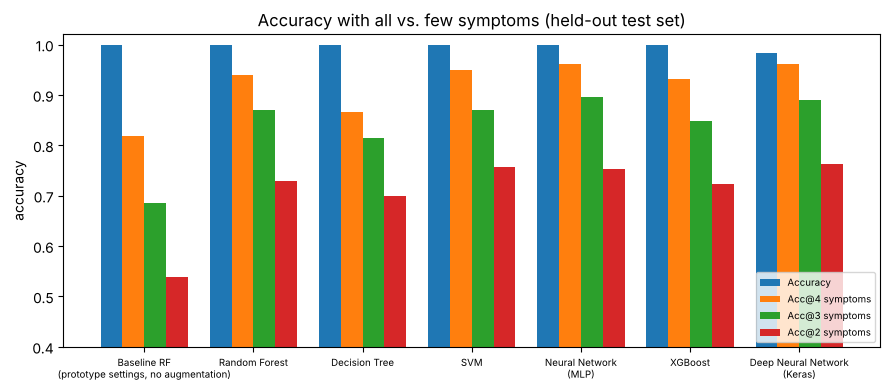

In [10]:
fig, ax = plt.subplots(figsize=(9, 4))
names = list(full_table.index); w = 0.2
for j, k in enumerate(["Accuracy", "Acc@4 symptoms", "Acc@3 symptoms", "Acc@2 symptoms"]):
    ax.bar(np.arange(len(names)) + j * w, full_table[k].astype(float).values, w, label=k)
ax.set_xticks(np.arange(len(names)) + 1.5 * w)
ax.set_xticklabels([n.replace(" (", "\n(") for n in names], fontsize=7)
ax.set_ylim(0.4, 1.02); ax.set_ylabel("accuracy"); ax.set_title("Accuracy with all vs. few symptoms (held-out test set)")
ax.legend(fontsize=7, loc="lower right"); plt.tight_layout()
plt.savefig("Notebooks/figures/model_comparison.png", dpi=150); plt.show()

### Reading the table
* With **all symptoms**, every model reaches 100 % on the held-out unique patterns, so the SRS target (NFR-08, ≥ 85 %) is met by all of them.
* The models differ when **few symptoms** are given — the situation of a real chat. Augmentation lifts every model well above the baseline.
* The selected model has the best 5-fold cross-validated robust score. Scores within 0.5 percentage points count as tied,
  and ties go to Random Forest because it is fast and interpretable (feature importance).

## 7. Selected model: errors with sparse input and feature importance

Selected model: Random Forest | tuned parameters: {'max_depth': None, 'min_samples_leaf': 2, 'n_estimators': 200}


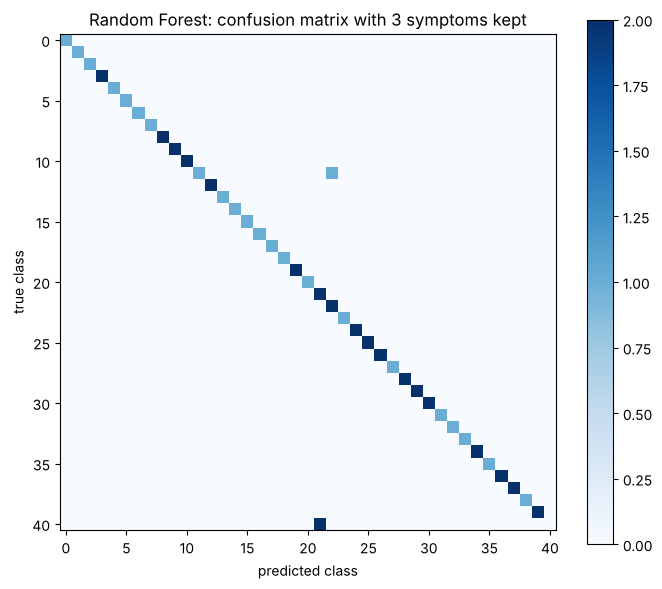

3 of 61 test rows misclassified with 3 symptoms. Examples:
  true: hepatitis A                  predicted: Hepatitis D
  true: Dengue                       predicted: Hepatitis E
  true: hepatitis A                  predicted: Hepatitis D


In [11]:
best_name = run["best"]; best = run["results"][best_name]["estimator"]
print("Selected model:", best_name, "| tuned parameters:", run["results"][best_name]["best_params"])

rng = np.random.default_rng(7)
Xs = trainer.keep_k_symptoms(X_te, 3, rng)
pred = best.predict(Xs)
cm = confusion_matrix(y_te, pred, labels=range(n_classes))
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm, cmap="Blues"); ax.set_title(f"{best_name}: confusion matrix with 3 symptoms kept")
ax.set_xlabel("predicted class"); ax.set_ylabel("true class"); plt.colorbar(im); plt.tight_layout()
plt.savefig("Notebooks/figures/confusion_matrix_3_symptoms.png", dpi=150); plt.show()

wrong = [(le.classes_[t], le.classes_[p]) for t, p in zip(y_te, pred) if t != p]
print(f"{len(wrong)} of {len(y_te)} test rows misclassified with 3 symptoms. Examples:")
for t, p in wrong[:8]: print(f"  true: {t:<28} predicted: {p}")

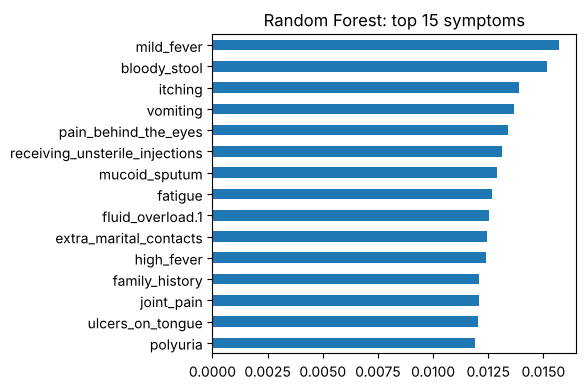

In [12]:
if hasattr(best, "feature_importances_"):
    imp = pd.Series(best.feature_importances_, index=run["symptom_columns"]).sort_values(ascending=False).head(15)
    ax = imp[::-1].plot.barh(figsize=(6, 4), title=f"{best_name}: top 15 symptoms")
    plt.tight_layout(); plt.savefig("Notebooks/figures/feature_importance.png", dpi=150); plt.show()

## 8. Sanity check with the SRS test inputs (TC-03a / TC-03b)

In [13]:
def probe(symptoms):
    cols = run["symptom_columns"]; v = np.zeros((1, len(cols)))
    for s in symptoms: v[0, cols.index(s)] = 1
    p = best.predict_proba(v)[0]; top = np.argsort(p)[::-1][:3]
    return [(le.classes_[i], round(float(p[i]) * 100, 1)) for i in top]

print("headache, fever, nausea ->", probe(["headache", "high_fever", "nausea"]))
print("cough only             ->", probe(["cough"]))
print("fatigue only           ->", probe(["fatigue"]))

headache, fever, nausea -> [('Malaria', 24.6), ('Typhoid', 22.8), ('(vertigo) Paroymsal  Positional Vertigo', 10.3)]
cough only             -> [('Bronchial Asthma', 28.4), ('GERD', 16.5), ('Tuberculosis', 11.8)]
fatigue only           -> [('Varicose veins', 7.0), ('Hepatitis C', 6.4), ('Hepatitis D', 6.0)]


## 9. Save the selected model and the metrics (FR-12)
The bundle is **one `.pkl` file** that contains the model, the label encoder, the symptom columns and metadata.
The app registers it in the `ml_models` table and serves it as the production model.

In [14]:
import sklearn, datetime
slug = best_name.lower().replace(" ", "_").replace("(", "").replace(")", "")
path = f"Models/versions/model_v2_{slug}.pkl"
meta = {"name": best_name, "version": "v2", "params": run["results"][best_name]["best_params"],
        "sklearn_version": sklearn.__version__, "trained_at": datetime.datetime.now().isoformat(timespec="seconds"),
        "dataset": "Datasets/Training.csv (de-duplicated, 304 rows)",
        "metrics": trainer.json_safe_metrics(run, best_name)}
trainer.save_bundle(path, best, run["label_encoder"], run["symptom_columns"], meta)
print("Saved", path, f"({os.path.getsize(path)/1e6:.1f} MB)")

summary = {
    "settings": run["settings"], "split": run["split"], "cleaning_report": report,
    "selected": best_name, "saved_bundle": path,
    "baseline_prototype_rf": base_m,
    "models": {n: trainer.json_safe_metrics(run, n) for n in run["results"]},
    "keras_dnn": {**{k: float(v) for k, v in dnn_test.items()}, **{k: float(v) for k, v in dnn_cv.items()},
                  "epochs": len(hist.history["loss"]), "train_seconds": round(dnn_time, 1)},
}
json.dump(summary, open("Models/model_comparison.json", "w"), indent=2, default=str)
full_table.round(4).to_csv("Models/model_comparison.csv")
dnn.save("Models/versions/dnn_keras.keras")
print("Saved Models/model_comparison.json, Models/model_comparison.csv, Models/versions/dnn_keras.keras")

Saved Models/versions/model_v2_random_forest.pkl (7.0 MB)
Saved Models/model_comparison.json, Models/model_comparison.csv, Models/versions/dnn_keras.keras


## 10. Conclusions
| Finding | Evidence |
|---|---|
| Duplicate removal is necessary | 4,616 / 4,920 rows are duplicates; 100 % of the test rows of a raw 80/20 split are exact copies of training rows |
| 100 % accuracy is expected, not impressive | the dataset encodes each disease as a fixed symptom combination |
| Sparse input is the real challenge | baseline RF: ~54 % with 2 symptoms, ~69 % with 3 |
| Symptom-subset augmentation fixes most of it | tuned models: ~73–76 % with 2, ~87–90 % with 3 symptoms |
| Model choice | all models are close on this small dataset; Random Forest wins the tie-break among deployable `.pkl` models (interpretable, fast). The DNN is the deep-learning comparison |
| NFR-08 (≥ 85 % accuracy) | met by every model on the held-out test set |